# 07. 서울 에어비앤비 자치구 종합 분석
## 생활인구 구조 × 상권 유형 → RevPAR 최적화 전략

---

### 데이터 소스 & 병합

| 구분 | 파일 | 내용 | 기간 | 집계 단위 |
|------|------|------|------|-----------|
| **에어비앤비** | `seoul_airbnb_cleaned.csv` | TTM RevPAR·ADR·점유율 + 리스팅 속성 | 2024-10 ~ 2025-09 | 리스팅 → 자치구 집계 |
| **생활인구** | `monthly_population.csv` | 자치구별 주간·야간·외국인 생활인구 | 2024-10 ~ 2025-09 | 자치구×월 → TTM 평균 |

> **병합 기준** : `district` 조인 → 25개 자치구 × 구조 변수 통합 데이터셋 (`analysis_df`)

---

### 분석 구조 (STEP 0 ~ 6)

| STEP | 제목 | 핵심 질문 |
|------|------|-----------|
| **0** | 자치구 RevPAR 구조 탐색 | 자치구별 RevPAR 분포·상관 구조는? |
| **1** | 다변량 구조 모델 (Ridge) | 어떤 구조 변수가 RevPAR를 설명하는가? |
| **2** | RevPAR 구조 분해 | ADR 주도형 vs 점유율 주도형 자치구는? |
| **3** | PCA 기반 구조 축 추출 | 서울 자치구의 핵심 구조 축은 무엇인가? |
| **4** | 4분면 시장 분류 | 수요·공급 구조로 자치구를 어떻게 분류하는가? |
| **5** | 가격 탄력성 분석 | ADR·점유율의 RevPAR 탄력성은 시장 유형별로 어떻게 다른가? |
| **6** | 잔차 성과 분석 | 구조 예측 대비 실제 성과 격차가 있는 자치구는? |

In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import seaborn as sns
from scipy import stats
import warnings, os

warnings.filterwarnings('ignore')
%matplotlib inline

# seaborn 스타일 먼저 설정 → 그 위에 폰트 덮어쓰기 (순서 중요!)
sns.set_style("whitegrid")
for font in ['Malgun Gothic', 'NanumGothic', 'AppleGothic']:
    try:
        mpl.rcParams['font.family'] = font
        break
    except Exception:
        pass
mpl.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# 경로 설정 (notebooks/ 또는 프로젝트 루트 실행 모두 지원)
_nb_dir = os.path.abspath('')
PARENT_DIR = os.path.dirname(_nb_dir) if os.path.basename(_nb_dir) == 'notebooks' else _nb_dir

RAW_PATH    = os.path.join(PARENT_DIR, 'data', 'raw',      'seoul_airbnb_cleaned.csv')
POP_PATH    = os.path.join(PARENT_DIR, 'data', 'external', 'monthly_population.csv')
REPORTS_DIR = os.path.join(PARENT_DIR, 'reports')
PROC_DIR    = os.path.join(PARENT_DIR, 'data', 'processed')
os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(PROC_DIR, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print(f"프로젝트 루트: {PARENT_DIR}")
print("라이브러리 & 경로 설정 완료")

프로젝트 루트: c:\Users\noisn\seoul_airbnb_cleaned_2026-02-18_11-23\seoul_airbnb_cleaned_2026-02-18_11-23
라이브러리 & 경로 설정 완료


In [2]:
# 자치구 영문-한글 매핑 (병합용)
DISTRICT_MAP = {
    'Gangnam-gu':'강남구','Gangdong-gu':'강동구',
    'Gangbuk-gu':'강북구','Gangseo-gu':'강서구',
    'Gwanak-gu':'관악구','Gwangjin-gu':'광진구',
    'Guro-gu':'구로구','Geumcheon-gu':'금천구',
    'Nowon-gu':'노원구','Dobong-gu':'도봉구',
    'Dongdaemun-gu':'동대문구','Dongjak-gu':'동작구',
    'Mapo-gu':'마포구','Seodaemun-gu':'서대문구',
    'Seocho-gu':'서초구','Seongdong-gu':'성동구',
    'Seongbuk-gu':'성북구','Songpa-gu':'송파구',
    'Yangcheon-gu':'양천구','Yeongdeungpo-gu':'영등포구',
    'Yongsan-gu':'용산구','Eunpyeong-gu':'은평구',
    'Jongno-gu':'종로구','Jung-gu':'중구',
    'Jungnang-gu':'중랑구'
}

DISTRICT_MAP_INV = {v:k for k,v in DISTRICT_MAP.items()}

print("자치구 매핑 로드 완료")

자치구 매핑 로드 완료


---
## 데이터 준비: 에어비앤비 × 생활인구 병합

| | |
|------|------|
| **목적** | STEP 0~6 분석에 사용할 자치구 단위 통합 데이터셋 (`analysis_df`) 구성 |
| **방법** | ① 에어비앤비(32,061건) → `operation_status == 'Operating'` 필터 → 자치구별 집계<br>② 생활인구(12개월) → TTM 전체 평균 / L90 최근 3개월 평균으로 압축<br>③ `district` 기준 Inner Join → 25개 자치구 통합 |

> **분석 기준** : Operating 숙소만 포함 / 성과 지표는 TTM 기준 (`ttm_occupancy`, `ttm_avg_rate`, `ttm_revpar`)

### [1-0] 데이터 로드 & Operating 필터

In [3]:
raw_df = pd.read_csv(RAW_PATH)
pop_df = pd.read_csv(POP_PATH)
print(f"에어비앤비 원본: {raw_df.shape}")
print(f"월별 인구:       {pop_df.shape}")

# operation_status == 'Operating' 필터
df = raw_df[raw_df['operation_status'] == 'Operating'].copy()
print(f"\nOperating 필터 후: {len(df):,}개 ({len(df)/len(raw_df)*100:.1f}%)")
print("컬럼 샘플:", list(df.columns[:8]))

에어비앤비 원본: (32061, 42)
월별 인구:       (312, 7)

Operating 필터 후: 28,361개 (88.5%)
컬럼 샘플: ['baths', 'bedrooms', 'beds', 'district', 'extra_guest_fee', 'guests', 'instant_book', 'l90d_avg_rate']


### [1-1] 자치구 에어비앤비 집계 (TTM 기준)

`ttm_occupancy`, `ttm_avg_rate`, `ttm_revpar` 기준으로 자치구별 평균·중위값·숙소 수를 집계한다.

In [4]:
district_agg = df.groupby('district').agg(
    avg_occupancy   = ('ttm_occupancy', 'mean'),
    avg_adr         = ('ttm_avg_rate',  'mean'),
    avg_revpar      = ('ttm_revpar',    'mean'),
    median_revpar   = ('ttm_revpar',    'median'),
    avg_revenue     = ('ttm_revenue',   'mean'),
    median_revenue  = ('ttm_revenue',   'median'),
    listing_count   = ('ttm_revpar',    'count')
).reset_index()

print(f"집계 완료: {len(district_agg)}개 자치구")
district_agg.sort_values('avg_revpar', ascending=False).head(10)

집계 완료: 25개 자치구


,district,avg_occupancy,avg_adr,avg_revpar,median_revpar,avg_revenue,median_revenue,listing_count
12,Jongno-gu,0.332172,148339.462541,54190.117539,24141.40,1.925310e+07,8478321.0,2349
15,Mapo-gu,0.332963,133994.894848,47439.405805,24987.40,1.701334e+07,9003244.0,5823
24,Yongsan-gu,0.324794,131024.084268,42022.085630,22487.90,1.522249e+07,8001067.0,2540
13,Jung-gu,0.268722,148921.790997,41208.423283,16934.90,1.480188e+07,5998249.5,3204
6,Gangnam-gu,0.269477,133192.658543,32944.735263,15641.20,1.188015e+07,5670559.0,2643
11,Gwangjin-gu,0.323477,98811.385014,31394.160000,24180.20,1.136345e+07,8758426.0,725
5,Gangdong-gu,0.290683,104727.437420,31034.936923,24934.30,1.062768e+07,8504996.0,325
20,Seongdong-gu,0.263463,106412.341670,30365.085603,12773.05,1.063860e+07,4467134.0,514
21,Songpa-gu,0.248299,115324.377641,27803.793435,13483.60,1.003784e+07,4683652.0,914
17,Seocho-gu,0.244419,130773.321881,27583.137929,13954.90,1.000895e+07,5026307.0,1400


### [1-2] 인구 데이터 처리

- **TTM 평균**: 파일 전체 12개월 (2024-10 ~ 2025-09) — 연도 필터 없이 전체 사용
- **L90 평균**: 최근 3개월 (2025-07 ~ 2025-09)
- **파생 변수**: `pop_growth_ratio = l90_pop / ttm_pop`, `day_night_ratio`, `foreign_ratio`

In [5]:
pop_df.columns = ['year_month', 'district_kor', 'total_pop', 'domestic_pop',
                  'foreign_pop', 'day_pop', 'night_pop']

pop_clean = pop_df[pop_df['district_kor'] != '서울시'].copy()
pop_clean['year_month'] = pd.to_datetime(pop_clean['year_month'], format='%Y-%m')

# TTM: 파일 전체 12개월 (연도 필터 없음)
pop_ttm = pop_clean.copy()
# L90: 최근 3개월
l90_start = pd.Timestamp('2025-07-01')
pop_l90   = pop_clean[pop_clean['year_month'] >= l90_start]

print(f"TTM 기간: {pop_ttm['year_month'].min().strftime('%Y-%m')} ~ {pop_ttm['year_month'].max().strftime('%Y-%m')} ({pop_ttm['year_month'].nunique()}개월)")
print(f"L90 기간: {pop_l90['year_month'].min().strftime('%Y-%m')} ~ {pop_l90['year_month'].max().strftime('%Y-%m')} ({pop_l90['year_month'].nunique()}개월)")

# TTM 자치구별 평균
ttm_pop_df = pop_ttm.groupby('district_kor').agg(
    ttm_pop         = ('total_pop',  'mean'),
    ttm_day_pop     = ('day_pop',    'mean'),
    ttm_night_pop   = ('night_pop',  'mean'),
    ttm_foreign_pop = ('foreign_pop','mean'),
).reset_index()

# L90 자치구별 평균
l90_pop_df = pop_l90.groupby('district_kor').agg(
    l90_pop = ('total_pop', 'mean'),
).reset_index()

pop_combined = ttm_pop_df.merge(l90_pop_df, on='district_kor', how='inner')

# 파생 변수
pop_combined['pop_growth_ratio'] = pop_combined['l90_pop']       / pop_combined['ttm_pop']
pop_combined['day_night_ratio']  = pop_combined['ttm_day_pop']   / pop_combined['ttm_night_pop']
pop_combined['foreign_ratio']    = pop_combined['ttm_foreign_pop'] / pop_combined['ttm_pop']
# merge용 영문 district 생성
pop_combined['district'] = pop_combined['district_kor'].map(DISTRICT_MAP_INV)

print(f"\n인구 파생 변수 생성 완료: {len(pop_combined)}개 자치구")
pop_combined[['district','ttm_pop','l90_pop','pop_growth_ratio',
              'day_night_ratio','foreign_ratio']].head()

TTM 기간: 2024-10 ~ 2025-09 (12개월)
L90 기간: 2025-07 ~ 2025-09 (3개월)

인구 파생 변수 생성 완료: 25개 자치구


,district,ttm_pop,l90_pop,pop_growth_ratio,day_night_ratio,foreign_ratio
0,Gangnam-gu,863150.333333,875199.000000,1.013959,1.334963,0.021186
1,Gangdong-gu,528144.750000,532518.666667,1.008282,0.897121,0.002134
2,Gangbuk-gu,267641.000000,262410.666667,0.980458,0.886525,0.002737
3,Gangseo-gu,546936.750000,542132.666667,0.991216,0.972199,0.013944
4,Gwanak-gu,470739.916667,468722.000000,0.995713,0.855370,0.004889


In [6]:
analysis_df = district_agg.merge(pop_combined, on='district', how='inner')

analysis_df['listing_density'] = analysis_df['listing_count'] / analysis_df['ttm_pop'] * 10000
analysis_df['foreign_ratio_pct'] = analysis_df['foreign_ratio'] * 100
analysis_df = analysis_df.drop(columns=['district_kor'], errors='ignore')

print(f"최종 분석 테이블: {analysis_df.shape}")
analysis_df.head()

최종 분석 테이블: (25, 18)


,district,avg_occupancy,avg_adr,avg_revpar,median_revpar,avg_revenue,median_revenue,listing_count,ttm_pop,ttm_day_pop,ttm_night_pop,ttm_foreign_pop,l90_pop,pop_growth_ratio,day_night_ratio,foreign_ratio,listing_density,foreign_ratio_pct
0,Dobong-gu,0.254368,79813.828685,20613.606748,13606.20,7.315784e+06,4966266.0,163,258262.833333,239938.666667,271351.666667,416.083333,254664.666667,0.986068,0.884235,0.001611,6.311400,0.161108
1,Dongdaemun-gu,0.215757,70284.108316,17233.662060,5269.50,6.173510e+06,1857322.0,767,362689.250000,357744.083333,366221.750000,2936.750000,356345.333333,0.982509,0.976851,0.008097,21.147580,0.809715
2,Dongjak-gu,0.174136,61492.674675,12518.183495,1101.10,4.487471e+06,384468.0,721,379647.250000,355967.250000,396561.750000,1527.416667,373156.333333,0.982903,0.897634,0.004023,18.991314,0.402325
3,Eunpyeong-gu,0.244957,125630.147474,27118.973199,14694.40,9.703934e+06,5153717.0,347,422863.916667,383037.416667,451311.333333,1079.500000,417167.000000,0.986528,0.848721,0.002553,8.205950,0.255283
4,Gangbuk-gu,0.281375,67083.765018,19404.511250,11094.05,6.896198e+06,3700503.0,240,267641.000000,249045.416667,280923.250000,732.666667,262410.666667,0.980458,0.886525,0.002737,8.967236,0.273750


In [7]:
analysis_df.isnull().sum()

district             0
avg_occupancy        0
avg_adr              0
avg_revpar           0
median_revpar        0
avg_revenue          0
median_revenue       0
listing_count        0
ttm_pop              0
ttm_day_pop          0
ttm_night_pop        0
ttm_foreign_pop      0
l90_pop              0
pop_growth_ratio     0
day_night_ratio      0
foreign_ratio        0
listing_density      0
foreign_ratio_pct    0
dtype: int64

---
## STEP 0 — 자치구 RevPAR 구조 탐색

| | |
|------|------|
| **목적** | 서울 자치구별 RevPAR 분포와 주요 지표 간 기초 관계를 관찰하여, 이후 분석(STEP 1~6)의 방향을 설정한다 |
| **방법** | 자치구별 RevPAR 히스토그램 / ADR·점유율·구조 변수 상관 히트맵 / 기초 기술통계 |
| **인사이트 포인트** | RevPAR 분포 형태 / 주요 변수 간 상관 방향 / 이상값 자치구 식별 |

=== STEP 0: 기술통계 요약 ===


,count,mean,std,min,25%,50%,75%,max
median_revpar,25.0,12710.808000,7609.470677,852.300000,5892.300000,13577.100000,16006.950000,24987.400000
avg_adr,25.0,98739.157520,27720.828672,61492.674675,72729.697497,92646.366549,125630.147474,148921.790997
avg_occupancy,25.0,0.254447,0.048300,0.134789,0.232507,0.255817,0.281375,0.332963
foreign_ratio,25.0,0.015864,0.024599,0.001512,0.002737,0.007297,0.014520,0.118970
listing_density,25.0,27.694494,33.159015,3.752066,6.342103,14.533983,23.801327,124.595749
day_night_ratio,25.0,1.050149,0.213799,0.848721,0.897634,0.972199,1.094892,1.669559



[해석 포인트]
- RevPAR의 표준편차가 큰지 확인 → 자치구 간 격차 존재 여부
- ADR vs OCC 분산 비교 → 어떤 변수가 더 크게 움직이는지
- 구조 변수들의 분산이 충분한지 확인

=== RevPAR 상관계수 ===
median_revpar      1.000000
avg_occupancy      0.908150
avg_adr            0.717968
listing_density    0.527704
day_night_ratio    0.380078
foreign_ratio      0.325124
Name: median_revpar, dtype: float64

[해석 포인트]
- OCC, ADR 중 어떤 변수가 더 높은 상관을 보이는가?
- 구조 변수(외국인비율, 밀도 등)가 단순 상관에서도 의미 있는가?
- 단일 변수만으로 설명이 충분해 보이는가?



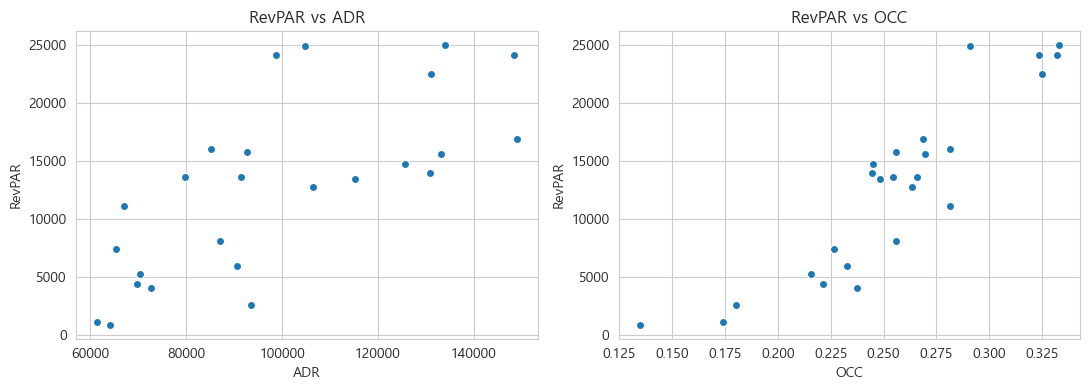


[해석 포인트]
- 직선 관계인가, 군집/이질 구조가 보이는가?
- 단순 선형 회귀로 충분히 설명 가능해 보이는가?



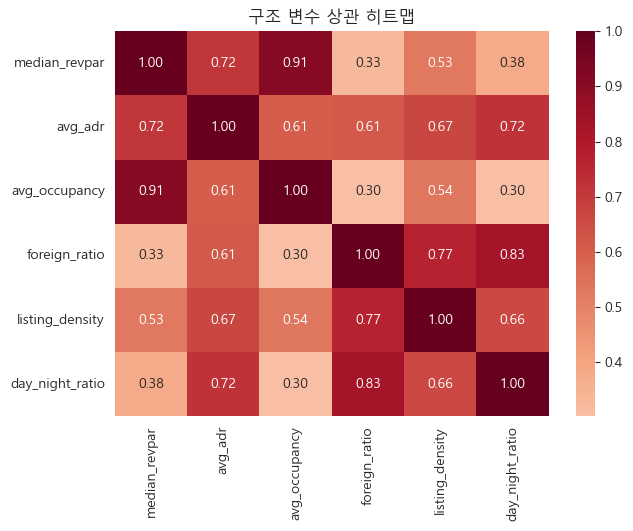


[해석 포인트]
- 외국인비율 ↔ 숙소밀도 상관 높은가?
- 주야비율 ↔ 외국인비율 연관 존재하는가?
- 변수 간 상호 연관성이 있다면 다중공선성 가능성 존재
→ 다변량 모델 및 Ridge 회귀 적용 필요성 확보


In [8]:
# 1. 분석 변수 설정
cols = [
    'median_revpar',
    'avg_adr',
    'avg_occupancy',
    'foreign_ratio',
    'listing_density',
    'day_night_ratio'
]

df = analysis_df[cols].copy()

print("=== STEP 0: 기술통계 요약 ===")
display(df.describe().T)

print("\n[해석 포인트]")
print("- RevPAR의 표준편차가 큰지 확인 → 자치구 간 격차 존재 여부")
print("- ADR vs OCC 분산 비교 → 어떤 변수가 더 크게 움직이는지")
print("- 구조 변수들의 분산이 충분한지 확인\n")


# 2. RevPAR 단순 상관 분석
corr = df.corr()

print("=== RevPAR 상관계수 ===")
print(corr['median_revpar'].sort_values(ascending=False))

print("\n[해석 포인트]")
print("- OCC, ADR 중 어떤 변수가 더 높은 상관을 보이는가?")
print("- 구조 변수(외국인비율, 밀도 등)가 단순 상관에서도 의미 있는가?")
print("- 단일 변수만으로 설명이 충분해 보이는가?\n")


# 3. 산점도 (RevPAR vs ADR / OCC)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(df['avg_adr'], df['median_revpar'], edgecolor='white')
axes[0].set_title("RevPAR vs ADR")
axes[0].set_xlabel("ADR")
axes[0].set_ylabel("RevPAR")

axes[1].scatter(df['avg_occupancy'], df['median_revpar'], edgecolor='white')
axes[1].set_title("RevPAR vs OCC")
axes[1].set_xlabel("OCC")
axes[1].set_ylabel("RevPAR")

plt.tight_layout()
plt.show()

print("\n[해석 포인트]")
print("- 직선 관계인가, 군집/이질 구조가 보이는가?")
print("- 단순 선형 회귀로 충분히 설명 가능해 보이는가?\n")

# 4. 상관 히트맵 (구조 변수 간 관계)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("구조 변수 상관 히트맵")
plt.show()

print("\n[해석 포인트]")
print("- 외국인비율 ↔ 숙소밀도 상관 높은가?")
print("- 주야비율 ↔ 외국인비율 연관 존재하는가?")
print("- 변수 간 상호 연관성이 있다면 다중공선성 가능성 존재")
print("→ 다변량 모델 및 Ridge 회귀 적용 필요성 확보")

---
## STEP 1 — 다변량 구조 모델 (Ridge 회귀)

| | |
|------|------|
| **목적** | 자치구의 RevPAR를 구조 변수로 정량적으로 설명하고, 각 변수의 기여도를 측정한다 |
| **방법** | 종속변수: `median_revpar` / 독립변수 5개: `avg_adr`, `avg_occupancy`, `foreign_ratio`, `listing_density`, `day_night_ratio`<br>→ StandardScaler 표준화 + Ridge(α=1.0) / 5-Fold CV |
| **출력** | 표준화 계수(β), R², 잔차 — STEP 6 잔차 성과 분석의 기초 데이터 |

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 한글 폰트
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# ── 변수 설정 ──
y_col  = 'median_revpar'
X_cols = ['avg_adr', 'avg_occupancy', 'foreign_ratio', 'listing_density', 'day_night_ratio']
label_map = {
    'avg_adr':         '평균 ADR',
    'avg_occupancy':   '평균 점유율',
    'foreign_ratio':   '외국인 비율',
    'listing_density': '숙소 밀도',
    'day_night_ratio': '주야 비율',
}

X_raw = analysis_df[X_cols].copy()
y     = analysis_df[y_col].copy()

# ── 표준화 ──
scaler  = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
X_sc_df  = pd.DataFrame(X_scaled, columns=X_cols)

# ── Ridge 회귀 ──
ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_scaled, y)
y_pred   = ridge.predict(X_scaled)
r2       = r2_score(y, y_pred)
n, p     = X_scaled.shape
adj_r2   = 1 - (1 - r2) * (n - 1) / (n - p - 1)

# ── 계수 테이블 ──
coef_df = pd.DataFrame({
    '변수':   [label_map[c] for c in X_cols],
    '표준화 계수': ridge.coef_,
    '절대값 계수': np.abs(ridge.coef_),
}).sort_values('절대값 계수', ascending=False).reset_index(drop=True)
coef_df.index += 1
coef_df['순위'] = coef_df.index

# ── VIF ──
X_vif = pd.DataFrame(X_scaled, columns=X_cols)
vif_df = pd.DataFrame({
    '변수':  [label_map[c] for c in X_cols],
    'VIF': [variance_inflation_factor(X_scaled, i) for i in range(p)]
}).sort_values('VIF', ascending=False).reset_index(drop=True)

print(f"=== Ridge 회귀 결과 ===")
print(f"R²       : {r2:.4f}")
print(f"Adj. R²  : {adj_r2:.4f}")
print(f"절편     : {ridge.intercept_:,.0f}")
print(f"\n=== 표준화 계수 (절대값 기준 정렬) ===")
print(coef_df[['순위','변수','표준화 계수','절대값 계수']].to_string(index=False))
print(f"\n=== VIF ===")
print(vif_df.to_string(index=False))

=== Ridge 회귀 결과 ===
R²       : 0.8740
Adj. R²  : 0.8409
절편     : 12,711

=== 표준화 계수 (절대값 기준 정렬) ===
 순위     변수      표준화 계수      절대값 계수
  1 평균 점유율 5299.012509 5299.012509
  2 평균 ADR 2455.580740 2455.580740
  3 외국인 비율 -578.409384  578.409384
  4  숙소 밀도 -115.556352  115.556352
  5  주야 비율   14.240610   14.240610

=== VIF ===
    변수      VIF
외국인 비율 4.718765
 주야 비율 4.443642
 숙소 밀도 3.376723
평균 ADR 3.266594
평균 점유율 1.932382


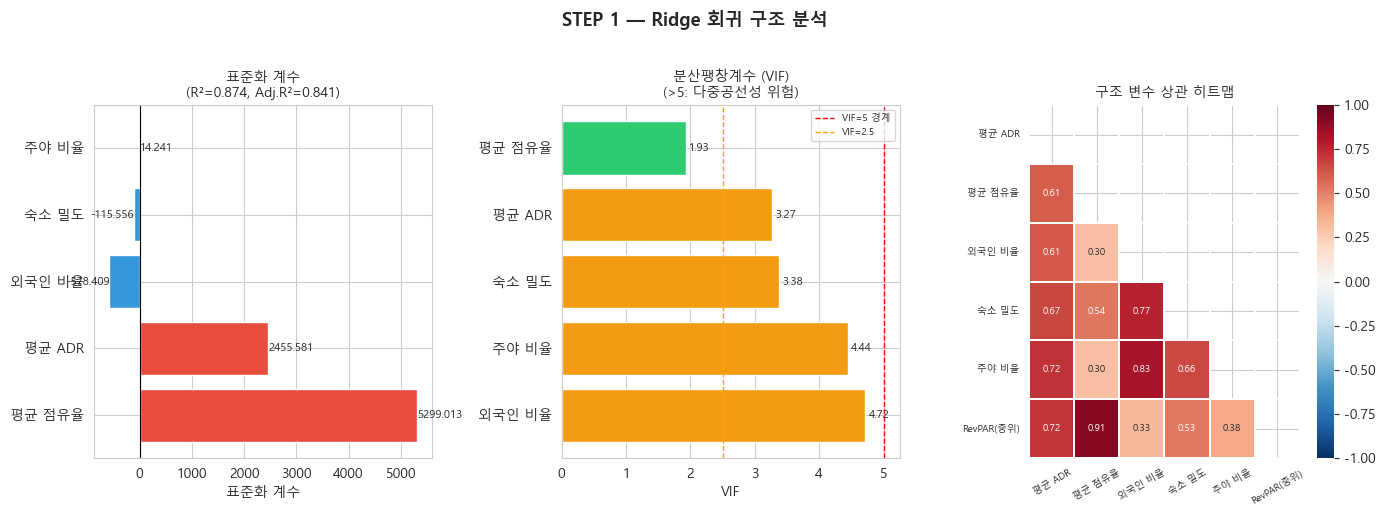

fig_07_step1_ridge_vif_corr.png 저장 완료


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('STEP 1 — Ridge 회귀 구조 분석', fontsize=13, fontweight='bold', y=1.02)

# (1) Ridge 표준화 계수
ax = axes[0]
colors = ['#e74c3c' if v > 0 else '#3498db' for v in coef_df['표준화 계수']]
ax.barh(coef_df['변수'], coef_df['표준화 계수'], color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'표준화 계수\n(R²={r2:.3f}, Adj.R²={adj_r2:.3f})', fontsize=10)
ax.set_xlabel('표준화 계수')
for i, v in enumerate(coef_df['표준화 계수']):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f'{v:.3f}',
            va='center', ha='left' if v >= 0 else 'right', fontsize=8)

# (2) VIF
ax2 = axes[1]
vif_colors = ['#e74c3c' if v > 5 else '#f39c12' if v > 2.5 else '#2ecc71' for v in vif_df['VIF']]
ax2.barh(vif_df['변수'], vif_df['VIF'], color=vif_colors, edgecolor='white')
ax2.axvline(5, color='red', linewidth=1, linestyle='--', label='VIF=5 경계')
ax2.axvline(2.5, color='orange', linewidth=1, linestyle='--', label='VIF=2.5')
ax2.set_title('분산팽창계수 (VIF)\n(>5: 다중공선성 위험)', fontsize=10)
ax2.set_xlabel('VIF')
ax2.legend(fontsize=7)
for i, v in enumerate(vif_df['VIF']):
    ax2.text(v + 0.05, i, f'{v:.2f}', va='center', fontsize=8)

# (3) 상관 히트맵
ax3 = axes[2]
corr_cols = X_cols + [y_col]
corr_labels = [label_map.get(c, c) for c in X_cols] + ['RevPAR(중위)']
corr_mat = analysis_df[corr_cols].corr()
corr_mat.index   = corr_labels
corr_mat.columns = corr_labels
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax3, annot_kws={'size': 7}, linewidths=0.3,
            vmin=-1, vmax=1)
ax3.set_title('구조 변수 상관 히트맵', fontsize=10)
ax3.tick_params(axis='x', rotation=30, labelsize=7)
ax3.tick_params(axis='y', rotation=0, labelsize=7)

plt.tight_layout()
plt.savefig('../reports/fig_07_step1_ridge_vif_corr.png', dpi=100, bbox_inches='tight')
plt.show()
print("fig_07_step1_ridge_vif_corr.png 저장 완료")

### STEP 1 인사이트

| 항목 | 값 |
|------|------|
| **R²** | 0.874 (Adj. R² = 0.841) → 5개 구조 변수로 RevPAR 분산의 **87%** 설명 |
| **1위: 평균 점유율** | β = +5,299 → 점유율 1σ 상승 시 RevPAR +₩5,299 |
| **2위: 평균 ADR** | β = +2,456 → 가격 1σ 상승 시 RevPAR +₩2,456 |
| **외국인 비율** | β = −578 → 공급 과밀 경쟁의 간접 효과로 RevPAR 압박 |
| **숙소 밀도** | β = −116 → 밀도 증가 시 경쟁 심화로 RevPAR 소폭 하락 |

> **핵심**: 점유율 > ADR 순서로 RevPAR 기여 — 가격 올리기보다 **점유율 방어**가 더 중요

---
## STEP 2 — RevPAR 구조 분해

| | |
|------|------|
| **목적** | RevPAR를 ADR 기여분과 점유율 기여분으로 분해하여, 각 자치구의 성과 창출 메커니즘을 파악한다 |
| **방법** | 로그 분해: `log(RevPAR_i / Med_RevPAR) = log(ADR_i / Med_ADR) + log(OCC_i / Med_OCC)`<br>→ 중앙값 기준 편차로 4분면 분류 |
| **분류 기준** | ADR 편차 > 0 이면 ADR 주도형 / OCC 편차 > 0 이면 점유율 주도형 |

In [11]:
# ── 수정된 RevPAR 구조 분해 (시장 중위값 대비 상대편차 기반) ──
# 핵심: log(OCC) < 0 문제를 시장 중위값 대비 편차로 우회
#   log(RevPAR_i/Med) = log(ADR_i/Med_ADR) + log(OCC_i/Med_OCC)
#   기여 비율 = |편차| / (|ADR편차| + |OCC편차|)  →  0~1, 합계=1 보장

df_decomp = analysis_df[['district','median_revpar','avg_adr','avg_occupancy']].copy()

# 시장 중위값
med_adr    = df_decomp['avg_adr'].median()
med_occ    = df_decomp['avg_occupancy'].median()
med_revpar = df_decomp['median_revpar'].median()

# 로그 편차 (양수=중위초과, 음수=중위미달)
df_decomp['log_adr_dev']    = np.log(df_decomp['avg_adr']       / med_adr)
df_decomp['log_occ_dev']    = np.log(df_decomp['avg_occupancy'] / med_occ)
df_decomp['log_revpar_dev'] = df_decomp['log_adr_dev'] + df_decomp['log_occ_dev']  # 항등식 검증용

# 절대값 기반 기여 비율
abs_adr = df_decomp['log_adr_dev'].abs()
abs_occ = df_decomp['log_occ_dev'].abs()
total   = (abs_adr + abs_occ).clip(lower=1e-9)

df_decomp['adr_contrib'] = abs_adr / total   # 0~1
df_decomp['occ_contrib'] = abs_occ / total   # 0~1  (ADR + OCC = 1 보장)

# 방향 표시
df_decomp['adr_dir'] = np.where(df_decomp['log_adr_dev'] >= 0, '▲', '▼')
df_decomp['occ_dir'] = np.where(df_decomp['log_occ_dev'] >= 0, '▲', '▼')

# 주도 유형 (절대 편차 크기 기준)
df_decomp['dominance'] = np.where(abs_adr >= abs_occ, 'ADR 주도형', '점유율 주도형')

# ── 결과 출력 ──
print(f"=== RevPAR 구조 분해 (시장 중위값 기준 상대편차) ===")
print(f"시장 중위 ADR: ₩{med_adr:,.0f}  |  중위 점유율: {med_occ:.1%}  |  중위 RevPAR: ₩{med_revpar:,.0f}\n")

disp = df_decomp[['district','median_revpar',
                   'log_adr_dev','adr_dir','log_occ_dev','occ_dir',
                   'adr_contrib','occ_contrib','dominance']].copy()
disp.columns = ['자치구','RevPAR','ADR편차(log)','ADR↑↓','OCC편차(log)','OCC↑↓','ADR기여','OCC기여','유형']
disp = disp.sort_values('ADR기여', ascending=False).reset_index(drop=True)
disp.index += 1
print(disp.to_string(float_format='%.3f'))

adr_n = (df_decomp['dominance'] == 'ADR 주도형').sum()
occ_n = (df_decomp['dominance'] == '점유율 주도형').sum()
print(f"\nADR 주도형: {adr_n}개  |  점유율 주도형: {occ_n}개")

# 편차 방향 조합별 요약
df_decomp['combo'] = df_decomp['adr_dir'] + 'ADR / ' + df_decomp['occ_dir'] + 'OCC'
print("\n=== 편차 방향 조합 ===")
print(df_decomp.groupby('combo')['district'].count().to_string())

=== RevPAR 구조 분해 (시장 중위값 기준 상대편차) ===
시장 중위 ADR: ₩92,646  |  중위 점유율: 25.6%  |  중위 RevPAR: ₩13,577

                자치구    RevPAR  ADR편차(log) ADR↑↓  OCC편차(log) OCC↑↓  ADR기여  OCC기여       유형
1       Seongbuk-gu  8104.500      -0.062     ▼       0.001     ▲  0.991  0.009  ADR 주도형
2         Dobong-gu 13606.200      -0.149     ▼      -0.006     ▼  0.963  0.037  ADR 주도형
3           Jung-gu 16934.900       0.475     ▲       0.049     ▲  0.906  0.094  ADR 주도형
4         Seocho-gu 13954.900       0.345     ▲      -0.046     ▼  0.883  0.117  ADR 주도형
5         Songpa-gu 13483.600       0.219     ▲      -0.030     ▼  0.880  0.120  ADR 주도형
6      Eunpyeong-gu 14694.400       0.305     ▲      -0.043     ▼  0.875  0.125  ADR 주도형
7        Gangnam-gu 15641.200       0.363     ▲       0.052     ▲  0.875  0.125  ADR 주도형
8      Seongdong-gu 12773.050       0.139     ▲       0.029     ▲  0.825  0.175  ADR 주도형
9        Gangbuk-gu 11094.050      -0.323     ▼       0.095     ▲  0.772  0.228  ADR 주도형
10         

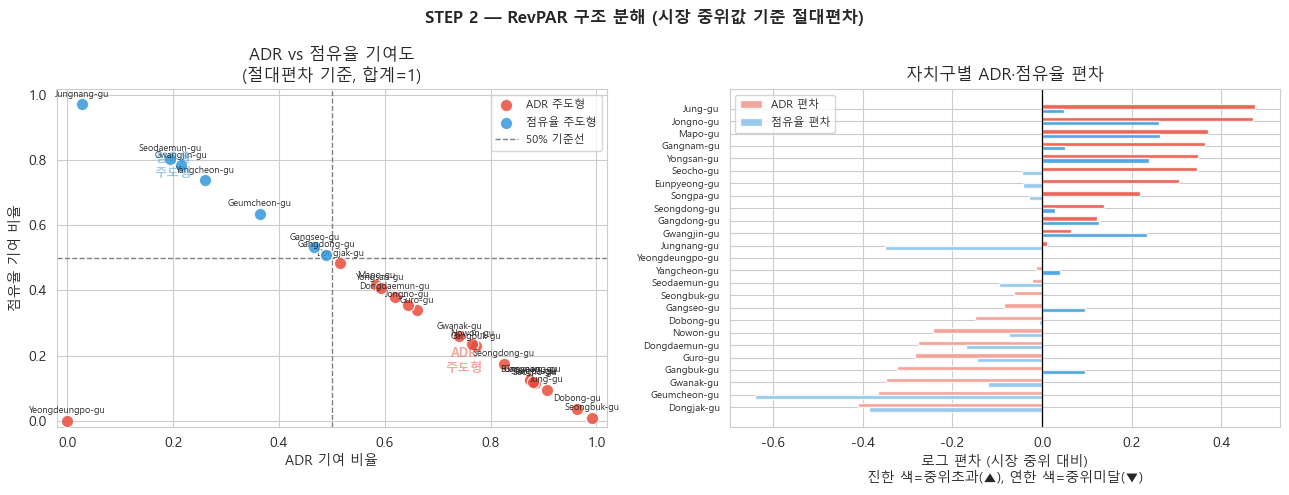

✅ fig_07_step2_revpar_decomp.png 저장 완료


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('STEP 2 — RevPAR 구조 분해 (시장 중위값 기준 절대편차)', fontsize=12, fontweight='bold')

color_map_d = {'ADR 주도형': '#e74c3c', '점유율 주도형': '#3498db'}

# (1) ADR vs OCC 기여 산점도 (0~1, 합계=1 → 반직선 위에 분포)
ax = axes[0]
for dom, grp in df_decomp.groupby('dominance'):
    ax.scatter(grp['adr_contrib'], grp['occ_contrib'],
               c=color_map_d[dom], label=dom, s=80, alpha=0.85, edgecolors='white', zorder=3)
    for _, row in grp.iterrows():
        ax.annotate(row['district'], (row['adr_contrib'], row['occ_contrib']),
                    fontsize=6.5, ha='center', va='bottom',
                    xytext=(0, 4), textcoords='offset points')
ax.axvline(0.5, color='gray', linewidth=1, linestyle='--', label='50% 기준선')
ax.axhline(0.5, color='gray', linewidth=1, linestyle='--')
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel('ADR 기여 비율')
ax.set_ylabel('점유율 기여 비율')
ax.set_title('ADR vs 점유율 기여도\n(절대편차 기준, 합계=1)')
ax.legend(fontsize=8)
# 영역 라벨
ax.text(0.75, 0.15, 'ADR\n주도형', ha='center', fontsize=9, color='#e74c3c', alpha=0.5, fontweight='bold')
ax.text(0.20, 0.75, '점유율\n주도형', ha='center', fontsize=9, color='#3498db', alpha=0.5, fontweight='bold')

# (2) 로그 편차 묶음 바차트 (ADR·OCC 중위 대비 편차)
ax2 = axes[1]
df_bar  = df_decomp.sort_values('log_adr_dev', ascending=True).reset_index(drop=True)
y_pos   = np.arange(len(df_bar))
height  = 0.35

adr_colors = ['#e74c3c' if v >= 0 else '#f1948a' for v in df_bar['log_adr_dev']]
occ_colors = ['#3498db' if v >= 0 else '#85c1e9' for v in df_bar['log_occ_dev']]

ax2.barh(y_pos + height / 2, df_bar['log_adr_dev'],
         height=height, color=adr_colors, alpha=0.85, label='ADR 편차')
ax2.barh(y_pos - height / 2, df_bar['log_occ_dev'],
         height=height, color=occ_colors, alpha=0.85, label='점유율 편차')
ax2.axvline(0, color='black', linewidth=0.9)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(df_bar['district'].tolist(), fontsize=7)
ax2.set_xlabel('로그 편차 (시장 중위 대비)\n진한 색=중위초과(▲), 연한 색=중위미달(▼)')
ax2.set_title('자치구별 ADR·점유율 편차')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../reports/fig_07_step2_revpar_decomp.png', dpi=100, bbox_inches='tight')
plt.show()
print("✅ fig_07_step2_revpar_decomp.png 저장 완료")

### STEP 2 인사이트

| 분류 | 자치구 수 | 특성 |
|------|----------|------|
| **ADR 주도형** | 18개 | ADR이 RevPAR 상승을 견인 — 가격 경쟁력 보유 |
| **점유율 주도형** | 7개 | 낮은 가격으로 점유율 확보 — 가격 인상 여력 있음 |

**4분면 세부 분류:**

| 4분면 | 자치구 수 | 포지션 |
|-------|----------|--------|
| ▲ADR / ▲OCC | 9개 | 프리미엄 균형형 (이상적) |
| ▲ADR / ▼OCC | 4개 | 고가·저점유 (점유율 개선 필요) |
| ▼ADR / ▲OCC | 4개 | 저가·고점유 (가격 인상 여력) |
| ▼ADR / ▼OCC | 8개 | 전반적 부진 (구조적 개선 필요) |

## STEP 3 — PCA 기반 구조 축 추출

| | |
|------|------|
| **목적** | 자치구 구조를 설명하는 잠재 차원을 추출하여 다변수 공간을 해석 가능한 2개 축으로 압축한다 |
| **방법** | 입력 변수 4개: `foreign_ratio`, `day_night_ratio`, `listing_density`, `listing_per_nightpop` <br> → StandardScaler + PCA(n_components=2) |
| **축 정의** | **PC1 = 수요 구성 축** — 외국인 비율·주야 인구 구조를 반영하며, 수요의 '크기'가 아닌 '성격'(관광·유동형 vs 주거·정주형)을 구분한다 <br> **PC2 = 공급 압력 축** — 숙소 밀도·공급/인구비율을 반영하며, 동일 수요 내 공급 강도 차이를 나타낸다 |

In [13]:
from sklearn.decomposition import PCA

# ── 파생 변수 생성 ──
df_pca = analysis_df.copy()
df_pca['listing_per_nightpop'] = df_pca['listing_count'] / df_pca['ttm_night_pop'].clip(lower=1)

pca_cols = ['foreign_ratio', 'day_night_ratio', 'listing_density',
            'listing_per_nightpop']
pca_labels = ['외국인비율', '주야비율', '숙소밀도', '공급/야간인구']

X_pca = df_pca[pca_cols].copy()
sc_pca = StandardScaler()
X_pca_scaled = sc_pca.fit_transform(X_pca)

pca = PCA(n_components=2, random_state=42)
pca.fit(X_pca_scaled)
scores = pca.transform(X_pca_scaled)

# ── 분산 설명 테이블 ──
var_table = pd.DataFrame({
    'PC':              [f'PC{i+1}' for i in range(2)],
    '고유값':          pca.explained_variance_,
    '분산 설명율(%)': pca.explained_variance_ratio_ * 100,
    '누적 설명율(%)': np.cumsum(pca.explained_variance_ratio_) * 100,
})
print("=== PCA 분산 설명 ===")
print(var_table.to_string(index=False, float_format='%.4f'))

# ── 로딩 행렬 ──
loading_df = pd.DataFrame(
    pca.components_.T,
    index=pca_labels,
    columns=[f'PC{i+1}' for i in range(2)]
)
print("\n=== PCA 로딩 행렬 ===")
print(loading_df.round(4).to_string())

# ── PC1·PC2 스코어를 df_pca에 추가 ──
df_pca['PC1'] = scores[:, 0]
df_pca['PC2'] = scores[:, 1]

print("\n=== 자치구 PC1·PC2 스코어 ===")
score_disp = df_pca[['district','PC1','PC2']].sort_values('PC1', ascending=False).reset_index(drop=True)
score_disp.index += 1
print(score_disp.to_string())

=== PCA 분산 설명 ===
 PC    고유값  분산 설명율(%)  누적 설명율(%)
PC1 3.5518    85.2440    85.2440
PC2 0.4591    11.0177    96.2618

=== PCA 로딩 행렬 ===
            PC1     PC2
외국인비율    0.5028  0.3120
주야비율     0.4689  0.6793
숙소밀도     0.5046 -0.5358
공급/야간인구  0.5223 -0.3926

=== 자치구 PC1·PC2 스코어 ===
           district       PC1       PC2
1           Jung-gu  6.072198  1.082511
2         Jongno-gu  3.381947  0.446231
3           Mapo-gu  3.376884 -2.253256
4        Yongsan-gu  2.323925 -1.068758
5        Gangnam-gu  0.860040  0.894590
6      Seodaemun-gu  0.717790 -0.073065
7         Seocho-gu  0.340933  0.830329
8   Yeongdeungpo-gu -0.018697  0.689456
9      Seongdong-gu -0.435427  0.417072
10    Dongdaemun-gu -0.556007 -0.133878
11       Gangseo-gu -0.712165  0.171874
12      Gwangjin-gu -0.714230 -0.204349
13        Songpa-gu -0.728123  0.238858
14     Geumcheon-gu -0.780812  0.628921
15        Gwanak-gu -0.855328 -0.608225
16       Dongjak-gu -0.890269 -0.379027
17          Guro-gu -1.013757  0.238785

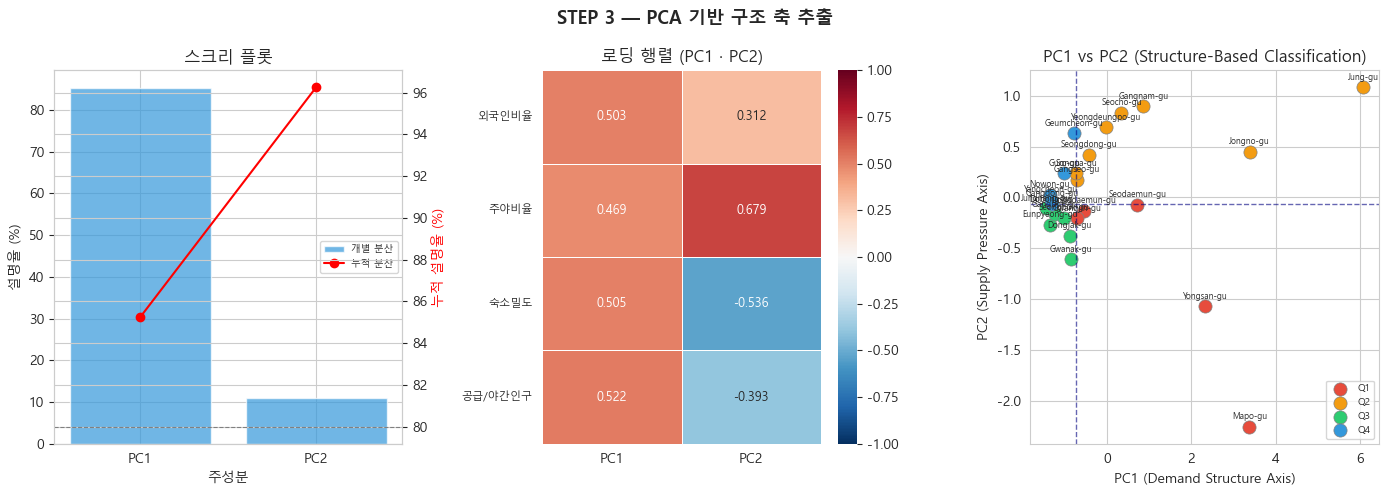

fig_07_step3_pca.png 저장 완료


<Figure size 640x480 with 0 Axes>

fig_07_step3_pca.png 저장 완료


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('STEP 3 — PCA 기반 구조 축 추출', fontsize=13, fontweight='bold')

# (1) Scree Plot
ax = axes[0]
pcs = [f'PC{i+1}' for i in range(2)]
ax.bar(pcs, pca.explained_variance_ratio_ * 100, color='#3498db', alpha=0.7, label='개별 분산')
ax2_twin = ax.twinx()
ax2_twin.plot(pcs, np.cumsum(pca.explained_variance_ratio_) * 100,
              'ro-', markersize=6, label='누적 분산')
ax2_twin.axhline(80, color='gray', linestyle='--', linewidth=0.8)
ax2_twin.set_ylabel('누적 설명율 (%)', color='red')
ax.set_xlabel('주성분')
ax.set_ylabel('설명율 (%)')
ax.set_title('스크리 플롯')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=7, loc='center right')

# (2) Loading 히트맵 (PC1, PC2만)
ax3 = axes[1]
load_2 = loading_df[['PC1', 'PC2']]
sns.heatmap(load_2, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            ax=ax3, linewidths=0.5, annot_kws={'size': 9}, vmin=-1, vmax=1)
ax3.set_title('로딩 행렬 (PC1 · PC2)')
ax3.tick_params(axis='y', labelsize=8, rotation=0)

# (3) PC1 vs PC2 산점도 (구조 기반 사분면)
ax4 = axes[2]
pc1_med = df_pca['PC1'].median()
pc2_med = df_pca['PC2'].median()

def structure_quad(row):
    if row['PC1'] >= pc1_med and row['PC2'] >= pc2_med:
        return 'Q2'
    elif row['PC1'] >= pc1_med and row['PC2'] < pc2_med:
        return 'Q1'
    elif row['PC1'] < pc1_med and row['PC2'] < pc2_med:
        return 'Q3'
    else:
        return 'Q4'

df_pca['structure_quad'] = df_pca.apply(structure_quad, axis=1)

quad_colors = {
    'Q1': '#e74c3c',
    'Q2': '#f39c12',
    'Q3': '#2ecc71',
    'Q4': '#3498db'
}

for quad, grp in df_pca.groupby('structure_quad'):
    ax4.scatter(
        grp['PC1'],
        grp['PC2'],
        color=quad_colors[quad],
        label=quad,
        s=90,
        edgecolors='gray',
        linewidths=0.5
    )

for _, row in df_pca.iterrows():
    ax4.annotate(row['district'], (row['PC1'], row['PC2']),
                 fontsize=6, ha='center', va='bottom',
                 xytext=(0, 4), textcoords='offset points')

ax4.axvline(pc1_med, color='navy', linewidth=1, linestyle='--', alpha=0.6)
ax4.axhline(pc2_med, color='navy', linewidth=1, linestyle='--', alpha=0.6)

ax4.set_xlabel('PC1 (Demand Structure Axis)')
ax4.set_ylabel('PC2 (Supply Pressure Axis)')
ax4.set_title('PC1 vs PC2 (Structure-Based Classification)')
ax4.legend(fontsize=7)

plt.tight_layout()
plt.savefig('../reports/fig_07_step3_pca.png', dpi=100, bbox_inches='tight')
plt.show()
print("fig_07_step3_pca.png 저장 완료")
ax4.set_ylabel('PC2 (Supply Pressure Axis)')
ax4.set_title('PC1 vs PC2 (Structure-Based Classification)')

plt.tight_layout()
plt.savefig('../reports/fig_07_step3_pca.png', dpi=100, bbox_inches='tight')
plt.show()
print("fig_07_step3_pca.png 저장 완료")

## STEP 3 인사이트 — 시장 구조 정의

**PC1 (수요 구성 축)** — 설명 분산 85.2%

외국인 비율과 주야 인구 구조를 반영한다. 수요의 크기가 아니라 **수요의 성격**을 측정하는 축이다.
- 높을수록 → 외국인 방문객·유동인구 중심의 관광·상업형 수요 구성
- 낮을수록 → 내국인·야간 정주인구 중심의 주거·생활형 수요 구성

**PC2 (공급 압력 축)** — 설명 분산 11.0%

숙소 밀도와 공급/야간인구 비율을 반영한다. **동일한 수요 구성 내에서 공급이 얼마나 집중되어 있는지**를 측정하는 축이다.
- 높을수록 → 공급 밀집, 상대적 경쟁 압력 큼
- 낮을수록 → 공급 여유, 경쟁 압력 낮음

> **두 축 합산 설명력 96.3%** — 25개 자치구의 시장 구조 대부분을 수요 구성 + 공급 압력 두 차원으로 설명할 수 있다.
>
> 4분면 분류(STEP 4)는 성과 우열이 아닌 **시장 환경 유형**을 나타낸다.

---
## STEP 4 — 4분면 시장 분류

| | |
|------|------|
| **목적** | 수요 구성 축(PC1)과 공급 압력 축(PC2)을 기준으로 서울 25개 자치구를 4가지 시장 환경 유형으로 분류한다 |
| **방법** | PC1·PC2 중앙값 기준 4분면 구분 → 시장 유형 레이블 부여 |

| 시장 유형 | PC1 | PC2 | 구조적 특징 |
|----------|-----|-----|------------|
| **Q1 프리미엄 관광거점** | High | Low | 관광·유동형 수요 구성 비중 상대적으로 높음 + 공급 여유 — 수요·공급 균형이 상대적으로 유리한 구조 |
| **Q2 과열 관광상권** | High | High | 관광·유동형 수요 구성 + 공급 집중 — 수요 집중도와 공급 경쟁이 함께 높은 구조 |
| **Q3 안정 주거상권** | Low | Low | 주거·정주형 수요 구성 + 공급 여유 — 안정적이나 수요 유형 전환 여지 제한적 |
| **Q4 공급과잉 외곽** | Low | High | 주거·정주형 수요 구성 + 공급 집중 — 수요 구성 대비 공급 압력이 상대적으로 높은 구조 |

> 각 유형은 성과(RevPAR)의 우열을 나타내지 않는다. 시장 환경 특성을 구조적으로 분류한 것이며, 동일 유형 내에서도 운영 역량에 따라 실제 성과 차이가 발생한다.

In [15]:
# ── 4분면 분류 ──
pc1_med = df_pca['PC1'].median()
pc2_med = df_pca['PC2'].median()

def classify_quadrant(row):
    if row['PC1'] >= pc1_med and row['PC2'] < pc2_med:
        return 'Q1: 프리미엄 관광거점'
    elif row['PC1'] >= pc1_med and row['PC2'] >= pc2_med:
        return 'Q2: 과열 관광상권'
    elif row['PC1'] < pc1_med and row['PC2'] < pc2_med:
        return 'Q3: 안정 주거상권'
    else:
        return 'Q4: 공급과잉 외곽'

df_pca['market_type'] = df_pca.apply(classify_quadrant, axis=1)

# ── 시장 유형별 KPI 요약 ──
summary = df_pca.groupby('market_type').agg(
    자치구수        = ('district', 'count'),
    중위RevPAR     = ('median_revpar', 'median'),
    평균ADR        = ('avg_adr', 'mean'),
    평균점유율      = ('avg_occupancy', 'mean'),
    숙소밀도        = ('listing_density', 'mean'),
).reset_index()
summary.columns.name = None

print("=== 최종 시장 분류 테이블 ===")
print(summary.to_string(index=False, float_format='%.2f'))

print("\n=== 자치구별 시장 유형 ===")
dist_type = df_pca[['district','market_type','PC1','PC2','median_revpar']].sort_values('market_type').reset_index(drop=True)
dist_type.index += 1
print(dist_type.to_string())

=== 최종 시장 분류 테이블 ===
  market_type  자치구수  중위RevPAR     평균ADR  평균점유율  숙소밀도
Q1: 프리미엄 관광거점     5  22487.90 104928.06   0.29 58.39
  Q2: 과열 관광상권     8  15688.05 120098.89   0.27 36.33
  Q3: 안정 주거상권     7   8104.50  82878.23   0.23 11.85
  Q4: 공급과잉 외곽     5   4354.50  80579.97   0.23  5.37

=== 자치구별 시장 유형 ===
           district    market_type       PC1       PC2  median_revpar
1        Yongsan-gu  Q1: 프리미엄 관광거점  2.323925 -1.068758       22487.90
2     Dongdaemun-gu  Q1: 프리미엄 관광거점 -0.556007 -0.133878        5269.50
3      Seodaemun-gu  Q1: 프리미엄 관광거점  0.717790 -0.073065        5892.30
4           Mapo-gu  Q1: 프리미엄 관광거점  3.376884 -2.253256       24987.40
5       Gwangjin-gu  Q1: 프리미엄 관광거점 -0.714230 -0.204349       24180.20
6         Songpa-gu    Q2: 과열 관광상권 -0.728123  0.238858       13483.60
7      Seongdong-gu    Q2: 과열 관광상권 -0.435427  0.417072       12773.05
8         Seocho-gu    Q2: 과열 관광상권  0.340933  0.830329       13954.90
9           Jung-gu    Q2: 과열 관광상권  6.072198  1.082511       169

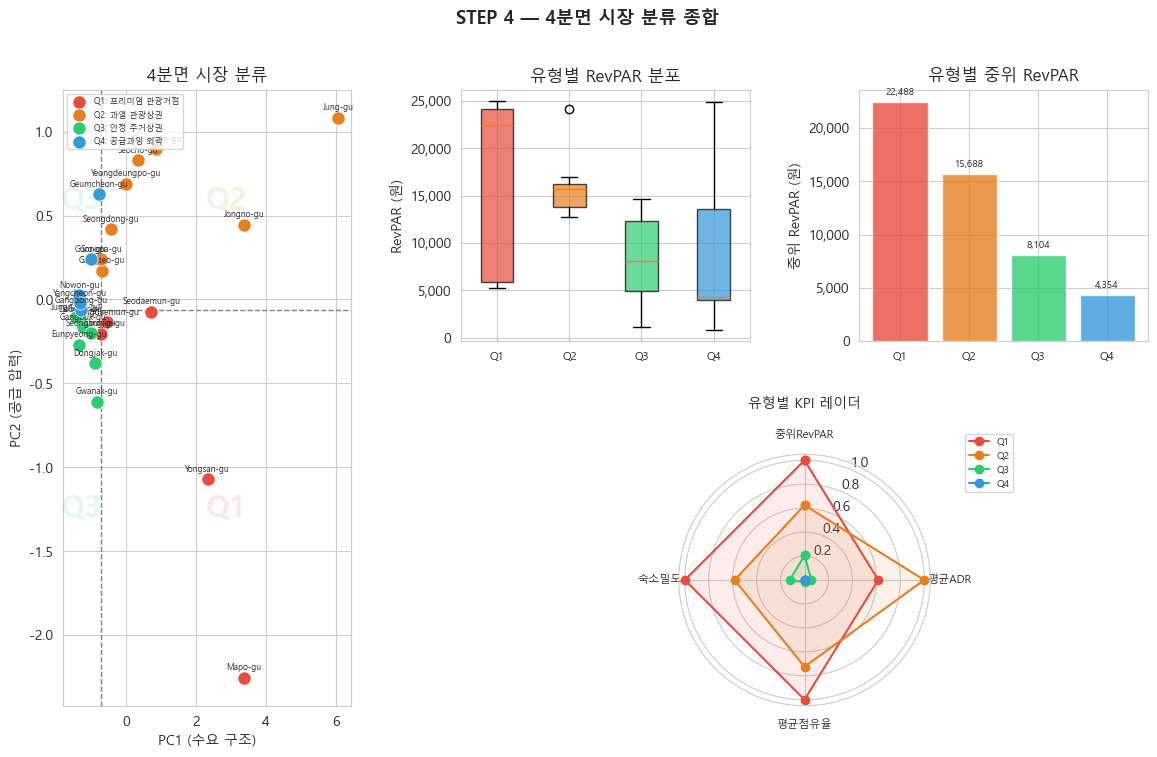

fig_07_step4_quadrant.png 저장 완료


In [16]:
from matplotlib.gridspec import GridSpec
import matplotlib.ticker as mticker

quad_colors = {
    'Q1: 프리미엄 관광거점': '#e74c3c',
    'Q2: 과열 관광상권':   '#e67e22',
    'Q3: 안정 주거상권':   '#2ecc71',
    'Q4: 공급과잉 외곽':   '#3498db',
}

fig = plt.figure(figsize=(14, 8))
gs  = GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)
fig.suptitle('STEP 4 — 4분면 시장 분류 종합', fontsize=13, fontweight='bold')

# (1) PC1 vs PC2 사분면
ax1 = fig.add_subplot(gs[:, 0])
for mtype, grp in df_pca.groupby('market_type'):
    ax1.scatter(grp['PC1'], grp['PC2'], c=quad_colors[mtype],
                label=mtype, s=90, edgecolors='white', linewidths=0.5, zorder=3)
    for _, row in grp.iterrows():
        ax1.annotate(row['district'], (row['PC1'], row['PC2']),
                     fontsize=6, ha='center', va='bottom',
                     xytext=(0, 4), textcoords='offset points')
ax1.axvline(pc1_med, color='gray', linewidth=1, linestyle='--')
ax1.axhline(pc2_med, color='gray', linewidth=1, linestyle='--')
ax1.set_xlabel('PC1 (수요 구조)')
ax1.set_ylabel('PC2 (공급 압력)')
ax1.set_title('4분면 시장 분류')
ax1.legend(fontsize=6, loc='upper left')

# 사분면 배경 라벨
x_min, x_max = ax1.get_xlim()
y_min, y_max = ax1.get_ylim()
ax1.text((x_min + pc1_med)/2, (pc2_med + y_max)/2, 'Q3', alpha=0.12, fontsize=22,
         fontweight='bold', ha='center', va='center', color='#2ecc71')
ax1.text((pc1_med + x_max)/2, (pc2_med + y_max)/2, 'Q2', alpha=0.12, fontsize=22,
         fontweight='bold', ha='center', va='center', color='#e67e22')
ax1.text((x_min + pc1_med)/2, (y_min + pc2_med)/2, 'Q3', alpha=0.12, fontsize=22,
         fontweight='bold', ha='center', va='center', color='#2ecc71')
ax1.text((pc1_med + x_max)/2, (y_min + pc2_med)/2, 'Q1', alpha=0.12, fontsize=22,
         fontweight='bold', ha='center', va='center', color='#e74c3c')

# (2) RevPAR 박스플롯
ax2 = fig.add_subplot(gs[0, 1])
types_order = list(quad_colors.keys())
data_bp = [df_pca[df_pca['market_type'] == t]['median_revpar'].values for t in types_order]
bp = ax2.boxplot(data_bp, patch_artist=True, notch=False)
for patch, mtype in zip(bp['boxes'], types_order):
    patch.set_facecolor(quad_colors[mtype])
    patch.set_alpha(0.7)
ax2.set_xticks(range(1, len(types_order)+1))
ax2.set_xticklabels([t.split(':')[0] for t in types_order], fontsize=8)
ax2.set_ylabel('RevPAR (원)')
ax2.set_title('유형별 RevPAR 분포')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# (3) KPI 비교 바차트 (중위RevPAR)
ax3 = fig.add_subplot(gs[0, 2])
bar_colors = [quad_colors[t] for t in summary['market_type']]
bars = ax3.bar(summary['market_type'].str.split(':').str[0],
               summary['중위RevPAR'], color=bar_colors, alpha=0.8, edgecolor='white')
for bar, val in zip(bars, summary['중위RevPAR']):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
             f'{val:,.0f}', ha='center', va='bottom', fontsize=7)
ax3.set_ylabel('중위 RevPAR (원)')
ax3.set_title('유형별 중위 RevPAR')
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax3.tick_params(axis='x', labelsize=8)

# (4) 레이더 차트 (4개 유형 × 4개 지표)
ax4 = fig.add_subplot(gs[1, 1:], projection='polar')
radar_cols = ['중위RevPAR', '평균ADR', '평균점유율', '숙소밀도']
radar_data = summary.set_index('market_type')[radar_cols]
radar_norm = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min() + 1e-9)
angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
angles += angles[:1]
ax4.set_theta_offset(np.pi / 2)
ax4.set_theta_direction(-1)
ax4.set_thetagrids(np.degrees(angles[:-1]), radar_cols, fontsize=8)
for mtype, row in radar_norm.iterrows():
    vals = row.tolist() + [row.iloc[0]]
    ax4.plot(angles, vals, 'o-', linewidth=1.5, label=mtype.split(':')[0], color=quad_colors[mtype])
    ax4.fill(angles, vals, alpha=0.1, color=quad_colors[mtype])
ax4.set_title('유형별 KPI 레이더', pad=15, fontsize=10)
ax4.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=7)

plt.savefig('../reports/fig_07_step4_quadrant.png', dpi=100, bbox_inches='tight')
plt.show()
print("fig_07_step4_quadrant.png 저장 완료")

### STEP 4 — 구조 유형 특징 요약

---

**Q1 프리미엄 관광거점** (5구: 마포구·용산구·서대문구·동대문구·광진구)

- **수요 성격**: 관광·유동형 — 외국인 비율 및 주간 유동인구 비중이 상대적으로 높음
- **공급 상태**: 공급 여유 — 숙소 밀도 및 공급/인구 비율 상대적으로 낮음
- **시장 환경**: 수요 구성과 공급 수준이 비교적 균형을 이루는 구조. 가격 전략 선택의 자율성이 상대적으로 높다.

---

**Q2 과열 관광상권** (8구: 중구·종로구·강남구·서초구·송파구·성동구·강서구·영등포구)

- **수요 성격**: 관광·상업형 — 외국인 유입과 주간 유동인구 집중도가 모두 높음
- **공급 상태**: 공급 집중 — 공급/인구 비율이 높아 경쟁 밀도가 큼
- **시장 환경**: 수요와 공급 압력이 동시에 높아 경쟁이 집중된 구조. 점유율 변동성이 클 수 있다.

---

**Q3 안정 주거상권** (7구: 도봉구·은평구·중랑구·강북구·성북구·동작구·관악구)

- **수요 성격**: 주거·정주형 — 야간 거주인구 비중이 높고 외국인·유동인구 비중 낮음
- **공급 상태**: 공급 여유 — 숙소 밀도 및 공급/인구 비율 낮음
- **시장 환경**: 수요와 공급이 모두 안정적이나 수요 유형 전환 여지가 제한적인 구조.

---

**Q4 공급과잉 외곽** (5구: 강동구·양천구·노원구·금천구·구로구)

- **수요 성격**: 주거·외곽형 — 야간 정주인구 중심, 외국인·유동인구 유입 낮음
- **공급 상태**: 공급 집중 — 수요 구성 대비 공급/인구 비율 상대적으로 높음
- **시장 환경**: 수요 구성 대비 공급 압력이 높은 구조.

---


---

**STEP 1 → 2 → 3·4 연결 스토리**

| 단계 | 핵심 발견 |
|------|---------|
| STEP 1 | 점유율·ADR이 RevPAR를 구조적으로 결정 (R²=0.874) |
| STEP 2 | 자치구별로 ADR 주도 vs 점유율 주도 패턴이 다름 |
| STEP 3·4 | 자치구별 성과 패턴 차이는 수요 구성(PC1)과 공급 압력(PC2)의 조합에 따라 다르게 나타난다 |

---
## STEP 5 — 구조 유형별 가격 반응 민감도 분석

| | |
|------|------|
| **목적** | ADR과 점유율의 RevPAR 반응 민감도를 정량화하고, 구조 유형(Q1~Q4)에 따라 가격·점유율 반응이 달라지는 패턴을 파악한다 |
| **방법** | OLS log-log 회귀: `log(median_revpar) ~ log(avg_adr) + log(avg_occupancy) + 구조 변수`<br>→ 계수 β = "설명변수 1% 증가 → RevPAR β% 변화" |
| **구조별 비교** | Q1~Q4 각각 별도 OLS 추정 → 구조 유형별 가격 반응 민감도 계수 비교 |

=== OLS log-log 탄력성 모델 ===
R²=0.9313  Adj.R²=0.9132  N=25

     변수      계수   표준오차     p값
ADR 탄력성  1.0380 0.3371 0.0062
OCC 탄력성  3.7414 0.3641 0.0000
  외국인비율  3.4434 4.8580 0.4871
   숙소밀도 -0.0068 0.0029 0.0328
   주야비율 -0.1689 0.5352 0.7558

핵심 탄력성:
  ADR 탄력성  : 1.0380 → ADR 1% 상승 시 RevPAR 1.04% 변화
  OCC 탄력성  : 3.7414 → 점유율 1% 상승 시 RevPAR 3.74% 변화


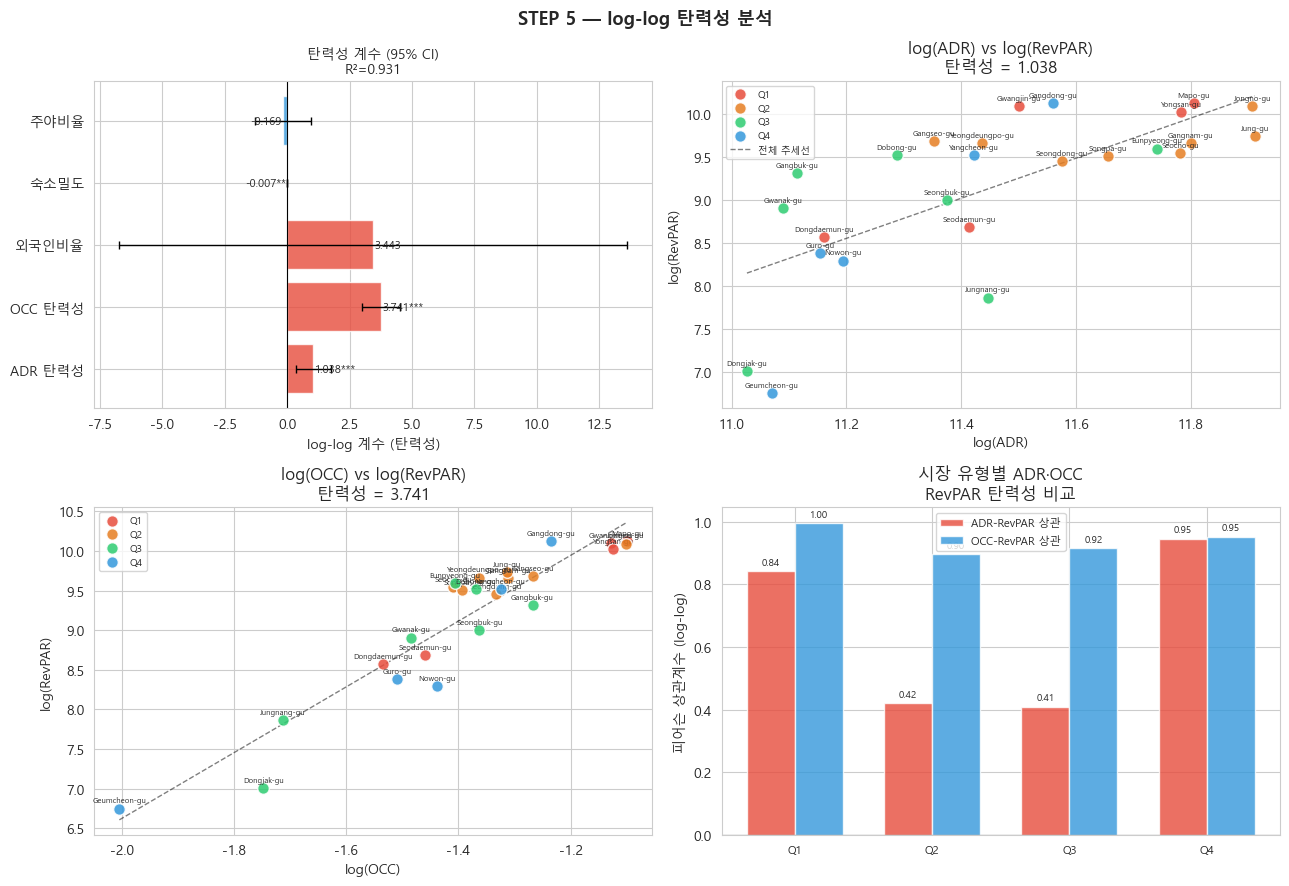

✅ fig_07_step5_elasticity.png 저장 완료


In [17]:
import statsmodels.api as sm

# ─── STEP 5: log-log 탄력성 모델 ───
df_ols = analysis_df.copy()
df_ols['market_type'] = df_pca['market_type'].values  # STEP 4에서 생성

df_ols['log_revpar'] = np.log(df_ols['median_revpar'].clip(lower=1))
df_ols['log_adr']    = np.log(df_ols['avg_adr'].clip(lower=1))
df_ols['log_occ']    = np.log(df_ols['avg_occupancy'].clip(lower=1e-6))

X_ols_df = df_ols[['log_adr', 'log_occ', 'foreign_ratio', 'listing_density', 'day_night_ratio']]
y_ols    = df_ols['log_revpar']
X_ols_c  = sm.add_constant(X_ols_df)

ols_model = sm.OLS(y_ols, X_ols_c).fit()

# ── 탄력성 테이블 ──
var_labels = ['ADR 탄력성', 'OCC 탄력성', '외국인비율', '숙소밀도', '주야비율']
ci = ols_model.conf_int()
elast_df = pd.DataFrame({
    '변수':   var_labels,
    '계수':   ols_model.params.values[1:],
    '표준오차': ols_model.bse.values[1:],
    'p값':    ols_model.pvalues.values[1:],
    'CI_L':   ci.values[1:, 0],
    'CI_H':   ci.values[1:, 1],
})

adr_e = ols_model.params['log_adr']
occ_e = ols_model.params['log_occ']

print(f"=== OLS log-log 탄력성 모델 ===")
print(f"R²={ols_model.rsquared:.4f}  Adj.R²={ols_model.rsquared_adj:.4f}  N={int(ols_model.nobs)}")
print()
print(elast_df[['변수','계수','표준오차','p값']].to_string(index=False, float_format='%.4f'))
print(f"\n핵심 탄력성:")
print(f"  ADR 탄력성  : {adr_e:.4f} → ADR 1% 상승 시 RevPAR {adr_e:.2f}% 변화")
print(f"  OCC 탄력성  : {occ_e:.4f} → 점유율 1% 상승 시 RevPAR {occ_e:.2f}% 변화")

# ─── 시각화 ───
quad_colors_s5 = {
    'Q1: 프리미엄 관광거점': '#e74c3c',
    'Q2: 과열 관광상권':    '#e67e22',
    'Q3: 안정 주거상권':    '#2ecc71',
    'Q4: 공급과잉 외곽':    '#3498db',
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('STEP 5 — log-log 탄력성 분석', fontsize=13, fontweight='bold')

# (1) 탄력성 계수 + CI 바차트
ax = axes[0, 0]
bar_colors_e = ['#e74c3c' if v > 0 else '#3498db' for v in elast_df['계수']]
ax.barh(elast_df['변수'], elast_df['계수'], color=bar_colors_e, alpha=0.8, edgecolor='white')
ax.errorbar(elast_df['계수'], elast_df['변수'],
            xerr=[elast_df['계수'] - elast_df['CI_L'],
                  elast_df['CI_H']  - elast_df['계수']],
            fmt='none', color='black', capsize=3, linewidth=1)
ax.axvline(0, color='black', linewidth=0.8)
for i, (v, p) in enumerate(zip(elast_df['계수'], elast_df['p값'])):
    sig = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''
    ax.text(v + (0.05 if v >= 0 else -0.05), i,
            f'{v:.3f}{sig}', va='center',
            ha='left' if v >= 0 else 'right', fontsize=8)
ax.set_title(f'탄력성 계수 (95% CI)\nR²={ols_model.rsquared:.3f}', fontsize=10)
ax.set_xlabel('log-log 계수 (탄력성)')

# (2) log(ADR) vs log(RevPAR) — 시장 유형별
ax2 = axes[0, 1]
for mtype, grp in df_ols.groupby('market_type'):
    ax2.scatter(grp['log_adr'], grp['log_revpar'],
                c=quad_colors_s5.get(mtype, 'gray'), label=mtype.split(':')[0],
                s=70, alpha=0.85, edgecolors='white', zorder=3)
    for _, row in grp.iterrows():
        ax2.annotate(row['district'], (row['log_adr'], row['log_revpar']),
                     fontsize=5.5, ha='center', va='bottom',
                     xytext=(0, 3), textcoords='offset points')
xr = np.linspace(df_ols['log_adr'].min(), df_ols['log_adr'].max(), 50)
slope_a, intcp_a, _, _, _ = stats.linregress(df_ols['log_adr'], df_ols['log_revpar'])
ax2.plot(xr, slope_a * xr + intcp_a, 'k--', linewidth=1, alpha=0.5, label='전체 추세선')
ax2.set_xlabel('log(ADR)')
ax2.set_ylabel('log(RevPAR)')
ax2.set_title(f'log(ADR) vs log(RevPAR)\n탄력성 = {adr_e:.3f}')
ax2.legend(fontsize=7, loc='upper left')

# (3) log(OCC) vs log(RevPAR) — 시장 유형별
ax3 = axes[1, 0]
for mtype, grp in df_ols.groupby('market_type'):
    ax3.scatter(grp['log_occ'], grp['log_revpar'],
                c=quad_colors_s5.get(mtype, 'gray'), label=mtype.split(':')[0],
                s=70, alpha=0.85, edgecolors='white', zorder=3)
    for _, row in grp.iterrows():
        ax3.annotate(row['district'], (row['log_occ'], row['log_revpar']),
                     fontsize=5.5, ha='center', va='bottom',
                     xytext=(0, 3), textcoords='offset points')
xr2 = np.linspace(df_ols['log_occ'].min(), df_ols['log_occ'].max(), 50)
slope_o, intcp_o, _, _, _ = stats.linregress(df_ols['log_occ'], df_ols['log_revpar'])
ax3.plot(xr2, slope_o * xr2 + intcp_o, 'k--', linewidth=1, alpha=0.5)
ax3.set_xlabel('log(OCC)')
ax3.set_ylabel('log(RevPAR)')
ax3.set_title(f'log(OCC) vs log(RevPAR)\n탄력성 = {occ_e:.3f}')
ax3.legend(fontsize=7, loc='upper left')

# (4) 시장 유형별 ADR·OCC → RevPAR 상관 비교
ax4 = axes[1, 1]
type_labels_s5, adr_corrs, occ_corrs = [], [], []
for mtype in quad_colors_s5:
    grp = df_ols[df_ols['market_type'] == mtype]
    if len(grp) >= 3:
        ra, _ = stats.pearsonr(grp['log_adr'], grp['log_revpar'])
        ro, _ = stats.pearsonr(grp['log_occ'], grp['log_revpar'])
        type_labels_s5.append(mtype.split(':')[0])
        adr_corrs.append(ra)
        occ_corrs.append(ro)
x_pos = np.arange(len(type_labels_s5))
w = 0.35
ax4.bar(x_pos - w/2, adr_corrs, w, label='ADR-RevPAR 상관',
        color='#e74c3c', alpha=0.8, edgecolor='white')
ax4.bar(x_pos + w/2, occ_corrs, w, label='OCC-RevPAR 상관',
        color='#3498db', alpha=0.8, edgecolor='white')
ax4.axhline(0, color='black', linewidth=0.8)
ax4.set_xticks(x_pos)
ax4.set_xticklabels(type_labels_s5, fontsize=8)
ax4.set_ylabel('피어슨 상관계수 (log-log)')
ax4.set_title('시장 유형별 ADR·OCC\nRevPAR 탄력성 비교')
ax4.legend(fontsize=8)
for i, (a, o) in enumerate(zip(adr_corrs, occ_corrs)):
    ax4.text(i - w/2, a + (0.02 if a >= 0 else -0.06), f'{a:.2f}', ha='center', fontsize=7)
    ax4.text(i + w/2, o + (0.02 if o >= 0 else -0.06), f'{o:.2f}', ha='center', fontsize=7)

plt.tight_layout()
plt.savefig('../reports/fig_07_step5_elasticity.png', dpi=100, bbox_inches='tight')
plt.show()
print("✅ fig_07_step5_elasticity.png 저장 완료")

### STEP 5 인사이트 — 구조별 가격·점유율 반응 민감도

> **STEP 5 역할**: 시장 구조 내에서 ADR과 점유율이 RevPAR에 얼마나 민감하게 반응하는지를 정량화한다.
> 구조 대비 실제 성과 차이는 STEP 6에서 분석한다.

---

**① 모델 결과 요약**

| 지표 | 수치 |
|------|------|
| 모델 (OLS log-log, N=25) | R² = 0.93 / Adj R² = 0.91 |
| ADR 반응 민감도 (β_ADR) | **1.04** (p=0.006) — ADR 1% 상승 → RevPAR 약 1.04% 상승 |
| OCC 반응 민감도 (β_OCC) | **3.74** (p<0.001) — 점유율 1% 상승 → RevPAR 약 3.74% 상승 |
| 숙소 밀도 효과 | β = −0.007 — 공급 밀도가 높을수록 RevPAR에 부정적 영향 |

---

**② ADR vs OCC 비교 해석**

OCC 민감도(3.74)가 ADR 민감도(1.04)의 약 **3.6배** 크다.

STEP 1 Ridge(OCC β=5,299 > ADR β=2,456)와 같은 방향 — 두 분석 모두 **점유율 방어가 가격 인상보다 RevPAR에 더 큰 영향**임을 지지한다.

이 지역에서 운영하는 호스트는 ADR 인상 전 점유율을 먼저 안정시키는 것이 효과적이다.



---
## STEP 6 — 잔차 성과 분석 (Residual Performance Analysis)

| | |
|------|------|
| **목적** | STEP 1 Ridge 모델의 구조 예측 대비 실제 성과 격차를 자치구별로 분류하여, 전략 기회 구역을 식별한다 |
| **방법** | Ridge 잔차 표준화 (Z-score) → ±0.5σ 기준 3단계 분류 |

| 성과 클래스 | 기준 | 의미 |
|-----------|------|------|
| **구조 초과 성과** | Z > +0.5 | 구조 대비 실제 성과 우수 → 운영 역량 또는 입지 프리미엄 |
| **구조 적합** | −0.5 ≤ Z ≤ +0.5 | 구조가 성과를 잘 예측 → 전형적 시장 행동 |
| **구조 미달 성과** | Z < −0.5 | 구조 대비 실제 성과 부진 → 개선 기회 존재 |

=== STEP 6: 잔차 성과 분류 ===
잔차 평균: -0원  표준편차: 2,701원

           district  median_revpar  ridge_predicted  ridge_residual  residual_z perf_class    market_type
1       Gangdong-gu        24934.3          17705.4          7228.9         2.7   구조 초과 성과    Q4: 공급과잉 외곽
2      Geumcheon-gu          852.3          -3496.4          4348.7         1.6   구조 초과 성과    Q4: 공급과잉 외곽
3       Gwangjin-gu        24180.2          20700.2          3480.0         1.3   구조 초과 성과  Q1: 프리미엄 관광거점
4   Yeongdeungpo-gu        15734.9          12388.6          3346.3         1.2   구조 초과 성과    Q2: 과열 관광상권
5         Dobong-gu        13606.2          11397.8          2208.4         0.8   구조 초과 성과    Q3: 안정 주거상권
6        Gangseo-gu        16007.0          14616.7          1390.3         0.5   구조 초과 성과    Q2: 과열 관광상권
7           Mapo-gu        24987.4          23902.8          1084.6         0.4      구조 적합  Q1: 프리미엄 관광거점
8           Jung-gu        16934.9          16151.4           783.5         0.3      구조 적합    Q2: 과열 

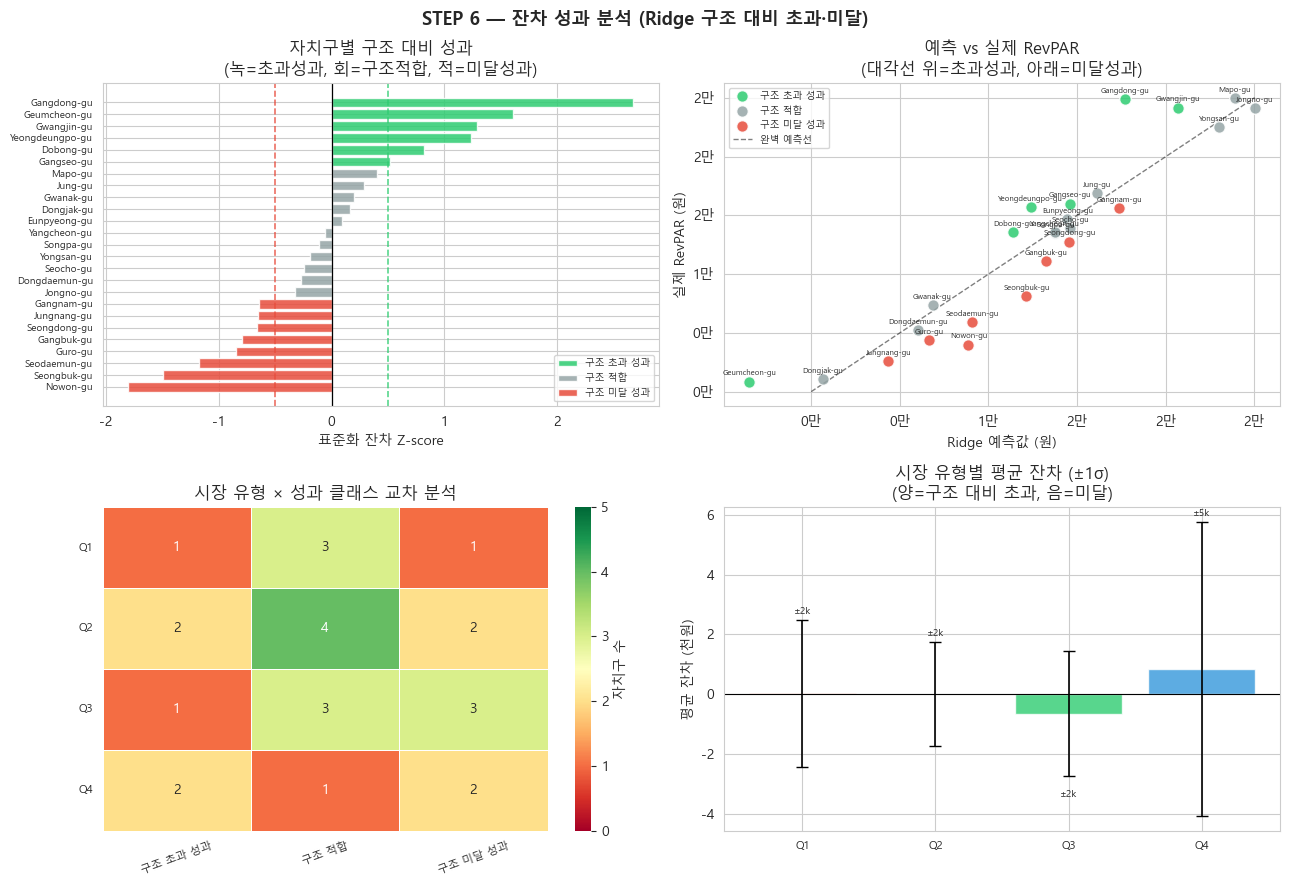

✅ fig_07_step6_residual.png 저장 완료

✅ 최종 분석 결과 저장: c:\Users\noisn\seoul_airbnb_cleaned_2026-02-18_11-23\seoul_airbnb_cleaned_2026-02-18_11-23\data\processed\district_pop_analysis.csv
   컬럼 27개: ['district', 'avg_occupancy', 'avg_adr', 'avg_revpar', 'median_revpar', 'avg_revenue', 'median_revenue', 'listing_count', 'ttm_pop', 'ttm_day_pop', 'ttm_night_pop', 'ttm_foreign_pop', 'l90_pop', 'pop_growth_ratio', 'day_night_ratio', 'foreign_ratio', 'listing_density', 'foreign_ratio_pct', 'market_type', 'PC1', 'PC2', 'adr_contrib', 'occ_contrib', 'dominance', 'ridge_residual', 'residual_z', 'perf_class']
   행 수: 25


In [18]:
# ─── STEP 6: Ridge 잔차 분석 ───
# STEP 1에서 계산된 ridge, y (actual), y_pred (predicted) 재사용
df_resid = analysis_df.copy()
df_resid['market_type']     = df_pca['market_type'].values
df_resid['ridge_predicted'] = y_pred
df_resid['ridge_residual']  = y.values - y_pred  # 실제 - 예측 (양수=초과, 음수=미달)

# 표준화 잔차 (Z-score)
resid_mean = df_resid['ridge_residual'].mean()
resid_std  = df_resid['ridge_residual'].std()
df_resid['residual_z'] = (df_resid['ridge_residual'] - resid_mean) / resid_std

# 성과 분류 (±0.5σ 기준)
df_resid['perf_class'] = np.where(
    df_resid['residual_z'] > 0.5,  '구조 초과 성과',
    np.where(df_resid['residual_z'] < -0.5, '구조 미달 성과', '구조 적합'))

# ── 결과 출력 ──
print("=== STEP 6: 잔차 성과 분류 ===")
print(f"잔차 평균: {resid_mean:,.0f}원  표준편차: {resid_std:,.0f}원\n")

disp_cols = ['district', 'median_revpar', 'ridge_predicted', 'ridge_residual', 'residual_z', 'perf_class', 'market_type']
disp_r = df_resid[disp_cols].sort_values('residual_z', ascending=False).reset_index(drop=True)
disp_r.index += 1
print(disp_r.to_string(float_format='%.1f'))

print("\n=== 시장 유형 × 성과 클래스 교차표 ===")
ct_full = pd.crosstab(df_resid['market_type'], df_resid['perf_class'])
print(ct_full)

print("\n▲ 구조 초과 성과 (Z > +0.5):")
top = df_resid[df_resid['perf_class'] == '구조 초과 성과'][['district','median_revpar','ridge_predicted','ridge_residual','market_type']]
print(top.sort_values('ridge_residual', ascending=False).to_string(index=False, float_format='%.0f'))

print("\n▼ 구조 미달 성과 (Z < −0.5):")
bot = df_resid[df_resid['perf_class'] == '구조 미달 성과'][['district','median_revpar','ridge_predicted','ridge_residual','market_type']]
print(bot.sort_values('ridge_residual').to_string(index=False, float_format='%.0f'))

# ─── 시각화 ───
perf_colors = {'구조 초과 성과': '#2ecc71', '구조 적합': '#95a5a6', '구조 미달 성과': '#e74c3c'}
quad_colors_s6 = {
    'Q1: 프리미엄 관광거점': '#e74c3c',
    'Q2: 과열 관광상권':    '#e67e22',
    'Q3: 안정 주거상권':    '#2ecc71',
    'Q4: 공급과잉 외곽':    '#3498db',
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('STEP 6 — 잔차 성과 분석 (Ridge 구조 대비 초과·미달)', fontsize=13, fontweight='bold')

# (1) 자치구별 표준화 잔차 바차트
ax = axes[0, 0]
df_sorted = df_resid.sort_values('residual_z').reset_index(drop=True)
bar_cols_r = [perf_colors[p] for p in df_sorted['perf_class']]
ax.barh(df_sorted['district'], df_sorted['residual_z'],
        color=bar_cols_r, alpha=0.85, edgecolor='white')
ax.axvline(0,    color='black',    linewidth=0.9)
ax.axvline( 0.5, color='#2ecc71', linewidth=1.2, linestyle='--', alpha=0.8)
ax.axvline(-0.5, color='#e74c3c', linewidth=1.2, linestyle='--', alpha=0.8)
ax.set_xlabel('표준화 잔차 Z-score')
ax.set_title('자치구별 구조 대비 성과\n(녹=초과성과, 회=구조적합, 적=미달성과)')
ax.tick_params(axis='y', labelsize=7)
legend_els = [mpatches.Patch(fc=c, label=l, alpha=0.85) for l, c in perf_colors.items()]
ax.legend(handles=legend_els, fontsize=7, loc='lower right')

# (2) 예측 vs 실제 산점도 (잔차 하이라이트)
ax2 = axes[0, 1]
for pclass in perf_colors:
    grp = df_resid[df_resid['perf_class'] == pclass]
    ax2.scatter(grp['ridge_predicted'], grp['median_revpar'],
                c=perf_colors[pclass], label=pclass, s=70, alpha=0.85,
                edgecolors='white', zorder=3)
    for _, row in grp.iterrows():
        ax2.annotate(row['district'],
                     (row['ridge_predicted'], row['median_revpar']),
                     fontsize=5.5, ha='center', va='bottom',
                     xytext=(0, 3), textcoords='offset points')
max_val = max(df_resid['ridge_predicted'].max(), df_resid['median_revpar'].max())
ax2.plot([0, max_val], [0, max_val], 'k--', linewidth=1, alpha=0.5, label='완벽 예측선')
ax2.set_xlabel('Ridge 예측값 (원)')
ax2.set_ylabel('실제 RevPAR (원)')
ax2.set_title('예측 vs 실제 RevPAR\n(대각선 위=초과성과, 아래=미달성과)')
ax2.legend(fontsize=7, loc='upper left')
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e4:.0f}만'))
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e4:.0f}만'))

# (3) 시장 유형 × 성과 클래스 히트맵
ax3 = axes[1, 0]
df_resid['mtype_short'] = df_resid['market_type'].str.split(':').str[0]
ct_plot = pd.crosstab(df_resid['mtype_short'], df_resid['perf_class'])
col_order = [c for c in ['구조 초과 성과', '구조 적합', '구조 미달 성과'] if c in ct_plot.columns]
ct_plot = ct_plot[col_order]
sns.heatmap(ct_plot, annot=True, fmt='d', cmap='RdYlGn', ax=ax3,
            linewidths=0.5, cbar_kws={'label': '자치구 수'}, vmin=0, vmax=5)
ax3.set_title('시장 유형 × 성과 클래스 교차 분석')
ax3.set_xlabel('')
ax3.set_ylabel('')
ax3.tick_params(axis='x', rotation=20, labelsize=8)
ax3.tick_params(axis='y', rotation=0, labelsize=8)

# (4) 시장 유형별 평균 잔차 ± std
ax4 = axes[1, 1]
type_resid_agg = df_resid.groupby('market_type').agg(
    mean_r = ('ridge_residual', 'mean'),
    std_r  = ('ridge_residual', 'std'),
).reset_index()
type_short_r = [t.split(':')[0] for t in type_resid_agg['market_type']]
bar_cols_t = [quad_colors_s6.get(t, 'gray') for t in type_resid_agg['market_type']]
ax4.bar(type_short_r, type_resid_agg['mean_r'] / 1000,
        color=bar_cols_t, alpha=0.8, edgecolor='white')
ax4.errorbar(type_short_r, type_resid_agg['mean_r'] / 1000,
             yerr=type_resid_agg['std_r'] / 1000,
             fmt='none', color='black', capsize=4, linewidth=1.2)
ax4.axhline(0, color='black', linewidth=0.8)
ax4.set_ylabel('평균 잔차 (천원)')
ax4.set_title('시장 유형별 평균 잔차 (±1σ)\n(양=구조 대비 초과, 음=미달)')
ax4.tick_params(axis='x', labelsize=8)
for i, (v, s) in enumerate(zip(type_resid_agg['mean_r'], type_resid_agg['std_r'])):
    offset = (s + 200) / 1000
    ax4.text(i, v / 1000 + (offset if v >= 0 else -offset - 0.5),
             f'±{s/1000:.0f}k', ha='center', fontsize=7)

plt.tight_layout()
plt.savefig('../reports/fig_07_step6_residual.png', dpi=100, bbox_inches='tight')
plt.show()
print("✅ fig_07_step6_residual.png 저장 완료")

# ─── 최종 분석 결과 저장 ───
final_df = analysis_df.copy()
final_df['market_type']    = df_pca['market_type'].values
final_df['PC1']            = df_pca['PC1'].values
final_df['PC2']            = df_pca['PC2'].values
final_df['adr_contrib']    = df_decomp['adr_contrib'].values
final_df['occ_contrib']    = df_decomp['occ_contrib'].values
final_df['dominance']      = df_decomp['dominance'].values
final_df['ridge_residual'] = df_resid['ridge_residual'].values
final_df['residual_z']     = df_resid['residual_z'].values
final_df['perf_class']     = df_resid['perf_class'].values

save_path = os.path.join(PROC_DIR, 'district_pop_analysis.csv')
final_df.to_csv(save_path, index=False, encoding='utf-8-sig')
print(f"\n✅ 최종 분석 결과 저장: {save_path}")
print(f"   컬럼 {len(final_df.columns)}개: {list(final_df.columns)}")
print(f"   행 수: {len(final_df)}")

### STEP 6 인사이트 — 구조 대비 실제 운영 역량 차이

> **STEP 6 역할**: 동일 구조 여건에서 실제 RevPAR가 예측치를 얼마나 초과·미달하는지를 Ridge 잔차 Z-score로 측정한다.
> 가격·점유율 반응 민감도는 STEP 5에서 완료했다.

---

**① 구조 초과 성과 자치구** _(Z > +0.5, 6구)_

- **해당 구**: 강동구·강서구·광진구·금천구·도봉구·영등포구
- **의미**: 구조 여건 대비 실제 RevPAR가 유의미하게 높다. 강동구(Q4)·도봉구(Q3)처럼 구조적으로 불리한 유형임에도 호스트 운영 역량이 구조를 초과하는 성과를 만들고 있다.
- **호스트 전략**: 현재 운영 방식(가격 설정·리뷰 관리·사진 구성)을 유지한다. 슈퍼호스트 지위 강화로 추가 프리미엄 확보를 노린다.

---

**② 구조 적합 자치구** _(|Z| ≤ 0.5, 11구)_

- **해당 구**: 관악구·동대문구·동작구·마포구·서초구·송파구·양천구·용산구·은평구·종로구·중구
- **의미**: 구조 여건과 실제 성과가 일치한다. 시장 구조가 예측하는 수준에서 운영 중이다.
- **호스트 전략**: 현상 유지보다 차별화 요소 발굴이 필요하다. 사진 수·리뷰 응답률·편의시설 추가로 경쟁 우위를 확보한다.

---

**③ 구조 미달 성과 자치구** _(Z < −0.5, 8구)_

- **해당 구**: 강남구·강북구·구로구·노원구·서대문구·성동구·성북구·중랑구
- **의미**: 구조 여건 대비 실제 RevPAR가 낮다. 특히 강남구(Q2)처럼 구조적 여건이 양호함에도 성과가 미달하는 경우, 운영 방식에 개선 여지가 크다.
- **호스트 전략**: 가격 구조를 재검토한다(저가 고착 탈피). 사진·설명 업데이트·리뷰 응답률 제고·슈퍼호스트 전환을 목표로 설정한다.

---

**STEP 0 → 6 분석 흐름 요약**

| 단계 | 분석 계층 | 결론 |
|------|----------|------|
| STEP 0 | RevPAR 분포 탐색 | 자치구별 편차 크고, 상위 구 집중 |
| STEP 1 | RevPAR 결정 변수 확인 | 점유율 > ADR 순 (R²=0.874) |
| STEP 2 | 성과 창출 메커니즘 분해 | 18개 ADR 주도 / 7개 점유율 주도 |
| STEP 3 | **시장 구조 정의** | 수요 구성 축(PC1)·공급 압력 축(PC2) 추출 |
| STEP 4 | **구조 유형 분류** | 4분면(Q1~Q4)으로 25개 자치구 분류 |
| STEP 5 | **가격·점유율 반응 분석** | β_OCC=3.74 >> β_ADR=1.04 → 점유율 방어 우선 |
| STEP 6 | **구조 대비 운영 성과 격차** | 초과(6구)·적합(11구)·미달(8구) 식별 |

---

**호스트 실행 전략 요약**

- **Q1 구조(마포·용산·서대문·동대문·광진)에서 운영한다면**: 점유율을 안정적으로 유지한 후 ADR 단계적 인상을 시도한다. 리뷰·사진 품질로 프리미엄 포지셔닝을 강화한다.
- **Q2 구조(중구·종로·강남·서초·송파·성동·강서·영등포)에서 운영한다면**: 공급 경쟁이 집중된 구조이므로 무리한 ADR 인상보다 즉시예약 활성화·유연한 취소 정책으로 점유율 방어를 우선한다.
- **Q3 구조(도봉·은평·중랑·강북·성북·동작·관악)에서 운영한다면**: 사진·편의시설 개선으로 점진적 ADR 인상에 도전한다. 장기 안정 운영이 유리한 구조다.
- **Q4 구조(강동·양천·노원·금천·구로)에서 운영한다면**: 가격 인하보다 차별화 콘텐츠와 성수기 집중 운영으로 점유율을 확보한다.
- **구조 미달 자치구에서 운영한다면**: 가격 구조 재검토(저가 고착 탈피)와 리스팅 품질 개선이 가장 급하다.

In [20]:
# 경로 존재 확인용
import os
print(os.getcwd())  # 현재 작업 디렉토리 확인

# 올바른 경로로 저장
df_pca[['district','market_type']].drop_duplicates().to_csv(
    '../data/processed/district_market_type.csv',
    index=False
)

c:\Users\noisn\seoul_airbnb_cleaned_2026-02-18_11-23\seoul_airbnb_cleaned_2026-02-18_11-23\notebooks
